In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import  files

print("OpenCV Version:", cv2.__version__)

OpenCV Version: 5.0.0


In [2]:
os.makedirs('images', exist_ok=True)

uploaded = files.upload()

image_path = None
for filename in uploaded.keys():
  image_path = os.path.join('images', filename)
  os.rename(filename, image_path)
  print(f"Image Saved: {image_path}")

Saving Original-Form-2.jpg to Original-Form-2.jpg
Image Saved: images/Original-Form-2.jpg


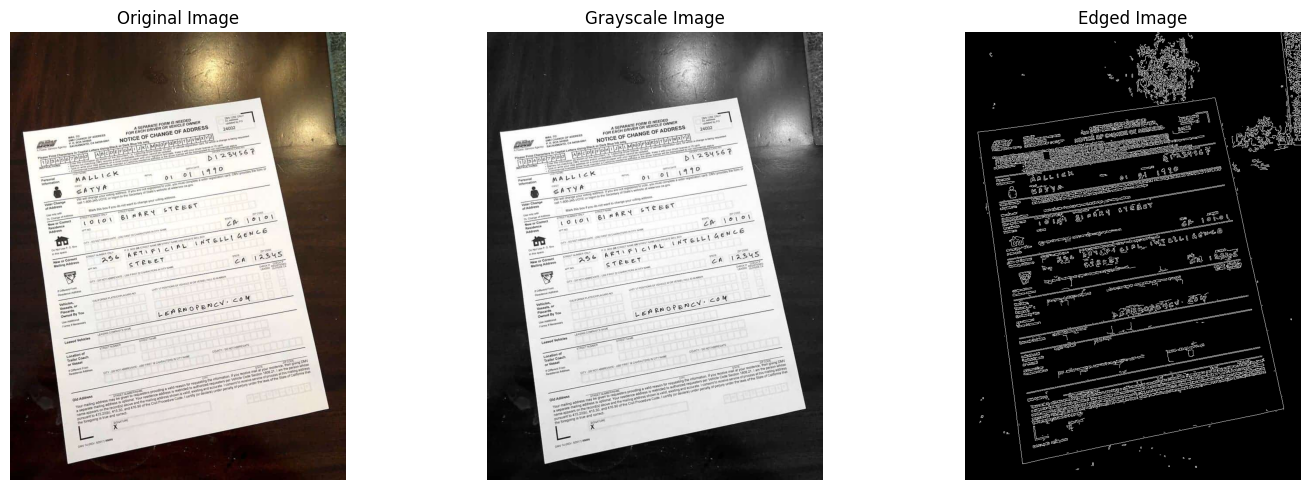

In [3]:
img = cv2.imread(image_path)
if img is None:
  print("Could Not Load Image")
else:
  max_dim = 1080
  h, w = img.shape[:2]
  if max(h, w) > max_dim:
    scale = max_dim / max(h, w)
    img = cv2.resize(img, None, fx = scale, fy = scale)
    print(f"Image Resized: {img.shape[1]}x{img.shape[0]}")

  orig_img = img.copy()

  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  blurred = cv2.GaussianBlur(gray, (5, 5), 0)
  edged = cv2.Canny(gray, 50, 150)

  fig, axs = plt.subplots(1, 3, figsize=(15, 5))

  axs[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  axs[0].set_title('Original Image')
  axs[0].axis('off')

  axs[1].imshow(cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB))
  axs[1].set_title('Grayscale Image')
  axs[1].axis('off')

  axs[2].imshow(cv2.cvtColor(edged, cv2.COLOR_GRAY2RGB))
  axs[2].set_title('Edged Image')
  axs[2].axis('off')

  plt.tight_layout()
  plt.show()

Number Of Contours: 269


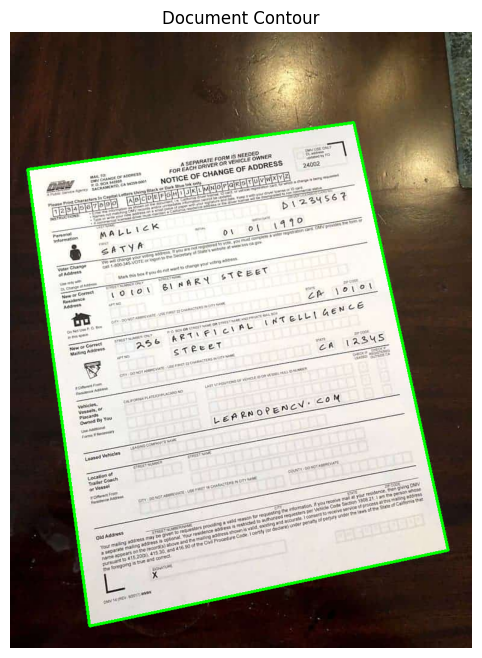

In [4]:
contours, hierarchy = cv2.findContours(edged, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print(f"Number Of Contours: {len(contours)}")

contours = sorted(contours, key=cv2.contourArea, reverse=True)

doc_contour = None
for contour in contours[:5]:
  peri = cv2.arcLength(contour, True)
  approx = cv2.approxPolyDP(contour, 0.02 * peri, True)

  if len(approx) == 4:
    doc_contour = approx
    break

if doc_contour is None:
  print("Could Not Find Document Contour")
  h, w = img.shape[:2]
  doc_contour = np.array([[0, 0], [w, 0], [w, h], [0, h]], dtype=np.float32)
else:
  (f"Document Corners Found: {len(doc_contour)} Points")

contour_img = orig_img.copy()
cv2.drawContours(img, [doc_contour], -1, (0, 255, 0), 3)

plt.figure(figsize=(10, 8))

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Document Contour')
plt.axis('off')

plt.show()

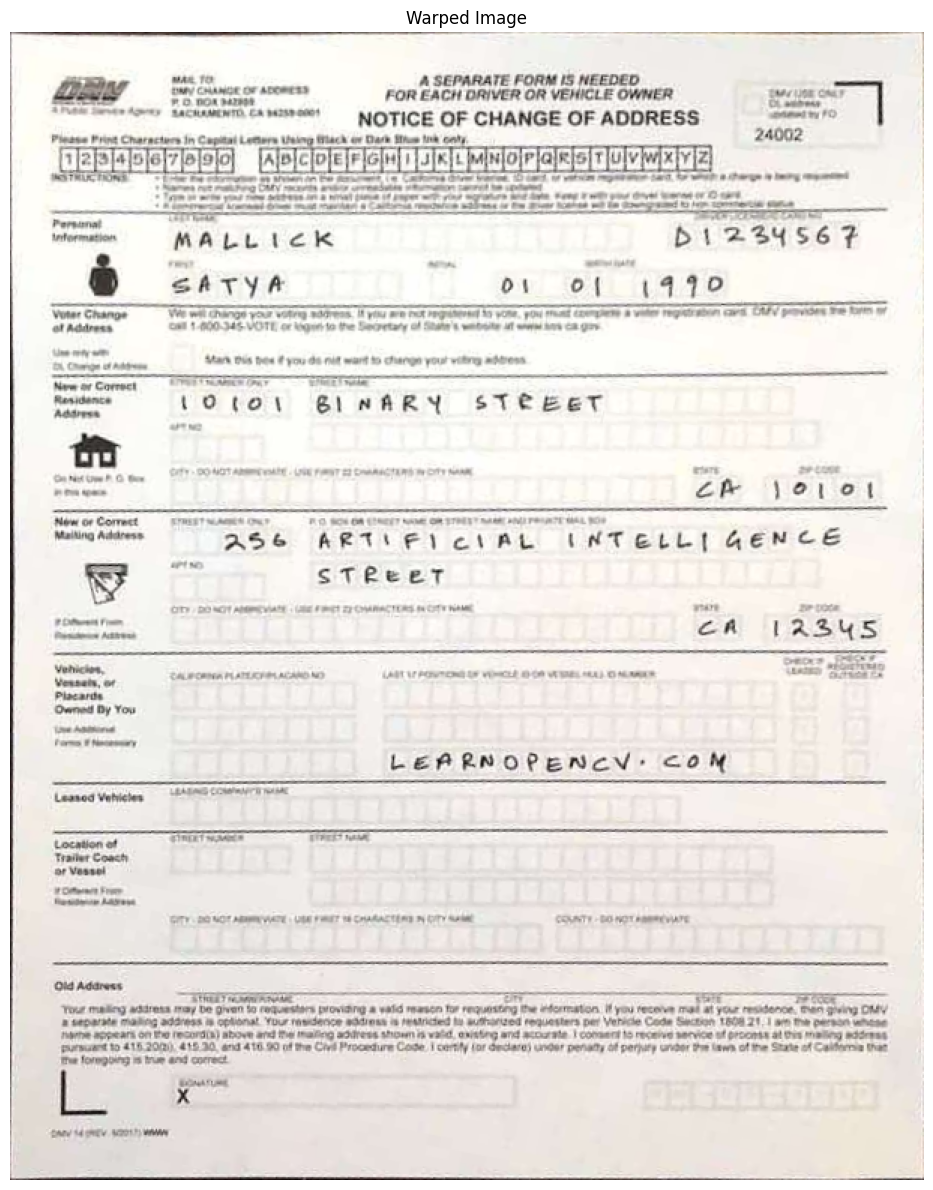

Warped Image Saved: Warped Image.jpg


In [5]:
def order_points(pts):
  rect = np.zeros((4, 2), dtype=np.float32)

  s = pts.sum(axis=1)
  rect[0] = pts[np.argmin(s)]

  rect[2] = pts[np.argmax(s)]

  diff = np.diff(pts, axis=1)
  rect[1] = pts[np.argmin(diff)]

  rect[3] = pts[np.argmax(diff)]

  return rect

pts = doc_contour.reshape(4, 2).astype(np.float32)
pts = order_points(pts)

widthA = np.linalg.norm(pts[0] - pts[1])
widthB = np.linalg.norm(pts[2] - pts[3])
maxWidth = max(int(widthA), int(widthB))

heightA = np.linalg.norm(pts[0] - pts[3])
heightB = np.linalg.norm(pts[1] - pts[2])
maxHeight = max(int(heightA), int(heightB))

dst = np.array([
    [0, 0],
    [maxWidth - 1, 0],
    [maxWidth - 1, maxHeight - 1],
    [0, maxHeight - 1]
], dtype=np.float32)

M = cv2.getPerspectiveTransform(pts, dst)
warped = cv2.warpPerspective(orig_img, M, (maxWidth, maxHeight))

plt.figure(figsize=(10, 12))

plt.imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
plt.title('Warped Image')
plt.axis('off')

plt.tight_layout()
plt.show()

output_path = 'Warped Image.jpg'
cv2.imwrite(output_path, warped)
print(f"Warped Image Saved: {output_path}")

In [6]:
if os.path.exists(output_path):
  files.download(output_path)
  print("Document Downloaded Successfully.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Document Downloaded Successfully.
